# Estructura del Notebook

En esta primera evaluación se construyen las siguientes etapas:

**Introducción y descripción del proyecto**

1. Importación de librerías
2. Configuración y reproducibilidad
3. Carga del dataset
4. Exploración inicial de los datos
5. Selección de nuestras 6 clases
6. Análisis exploratorio (EDA)
7. Preparación de los datos
8. Normalización
9. División de los datos
10. Construcción del MLP
11. Compilación y entrenamiento
12. Análisis de Loss y Accuracy
13. Evaluación final
14. Matriz de confusión
15. Análisis de errores
16. Conclusiones

# Clasificación de Lenguaje de Señas mediante una Red Neuronal MLP

## Técnicas Avanzadas de Machine Learning

### Descripción del proyecto

Este proyecto tiene como objetivo desarrollar un modelo de clasificación de imágenes utilizando una red neuronal tipo Perceptrón Multicapa (MLP).

Para ello, se utilizará el dataset **Sign Language MNIST**, el cual contiene imágenes en escala de grises de diferentes configuraciones manuales correspondientes a letras del lenguaje de señas.

Debido a los objetivos y tiempos establecidos para la evaluación, se definió una variante específica del problema utilizando seis clases seleccionadas del conjunto de datos:

- A
- C
- F
- K
- O
- Y

Las imágenes poseen una resolución de 28 × 28 píxeles, lo que representa un total de 784 características de entrada por imagen.

El modelo propuesto utilizará una única arquitectura MLP para aprender patrones presentes en los valores de los píxeles y clasificar cada imagen en una de las seis categorías seleccionadas.

La arquitectura base del modelo será:

784 características de entrada → primera capa con 128 neuronas con activación ReLU → segunda capa con 64 neuronas con activacion ReLU → 6 neuronas de salida con activación Softmax

El proyecto analizará no solamente la precisión obtenida por el modelo, sino también el comportamiento del proceso de entrenamiento mediante las métricas Loss, Validation Loss, Accuracy y Validation Accuracy. Finalmente, se realizará una evaluación utilizando métricas de clasificación y una matriz de confusión.

## 1. Importación de librerías

En esta sección se importan las librerías necesarias para realizar la carga, manipulación, visualización y preparación de los datos.

También se utilizarán librerías especializadas para construir y entrenar la red neuronal MLP.

In [1]:
# Manipulación de datos
import pandas as pd
import numpy as np
from time import time

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# División y evaluación de datos
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# TensorFlow y Keras
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.utils import set_random_seed, plot_model

# Para mostrar el diagrama de la red dentro del notebook
from IPython.display import Image, display

# Configuración visual
plt.rcParams["figure.figsize"] = (10, 6)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 2. Configuración de reproducibilidad

Los modelos de Machine Learning y Deep Learning pueden generar resultados diferentes entre ejecuciones debido a distintos procesos aleatorios, como la inicialización de los pesos de la red y la división de los datos.

Para facilitar la reproducibilidad del proyecto, se utilizará una semilla fija.

In [2]:
# Semilla para reproducibilidad
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
set_random_seed(SEED)

print(f"Semilla configurada: {SEED}")

Semilla configurada: 42


## 3. Carga del conjunto de datos

El dataset Sign Language MNIST se encuentra dividido originalmente en dos conjuntos:

- **Train:** utilizado para el desarrollo y entrenamiento del modelo.
- **Test:** reservado para realizar una evaluación final del desempeño.

Cada fila del dataset representa una imagen de 28 × 28 píxeles.

La columna `label` contiene la clase correspondiente a cada imagen, mientras que las demás 784 columnas representan los valores de intensidad de los píxeles.

In [3]:
import zipfile
import os

# Ruta del archivo ZIP (nombre esperado)
zip_path = "Sign Language MNIST.zip"

# Carpeta donde se extraerán los archivos
extract_path = "data"

# Eliminar cualquier archivo zip potencialmente corrupto o incompleto si existe
if os.path.exists(zip_path):
    os.remove(zip_path)
    print(f"Eliminado archivo existente: {zip_path}")

# Nombre del archivo zip que se descarga desde Kaggle
kaggle_downloaded_name = "sign-language-mnist.zip"

# Eliminar el archivo descargado por Kaggle si existe, para asegurar una descarga limpia
if os.path.exists(kaggle_downloaded_name):
    os.remove(kaggle_downloaded_name)
    print(f"Eliminado archivo de descarga de Kaggle existente: {kaggle_downloaded_name}")
!pip install -q kaggle
print(f"Descargando el dataset de Kaggle: 'datamunge/sign-language-mnist' a {os.getcwd()}")
!kaggle datasets download -d datamunge/sign-language-mnist -p .

# Verificar si el archivo se descargó correctamente
if os.path.exists(kaggle_downloaded_name):
    # Si el nombre descargado es diferente al nombre esperado, renómbralo
    if kaggle_downloaded_name != zip_path:
        os.rename(kaggle_downloaded_name, zip_path)
        print(f"Renombrado '{kaggle_downloaded_name}' a '{zip_path}'.")
    print("Dataset descargado correctamente.")
else:
    print(f"Error: El archivo zip descargado ('{kaggle_downloaded_name}') no fue encontrado.")
    print("Por favor, asegúrate de que tus credenciales de Kaggle API estén configuradas correctamente y el dataset exista.")

# Extraer el archivo ZIP
if os.path.exists(zip_path):
    try:
        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(extract_path)
        print("Dataset extraído correctamente en la carpeta 'data'.")
    except zipfile.BadZipFile:
        print(f"Error: El archivo '{zip_path}' aún no es un archivo zip válido después del intento de descarga.")
    except Exception as e:
        print(f"Ocurrió un error al intentar extraer el archivo: {e}")
else:
    print(f"Error: El archivo '{zip_path}' no existe para ser extraído después del intento de descarga.")

Descargando el dataset de Kaggle: 'datamunge/sign-language-mnist' a /content
Dataset URL: https://www.kaggle.com/datasets/datamunge/sign-language-mnist
License(s): CC0-1.0
100% 62.6M/62.6M [00:00<00:00, 150MB/s]

Renombrado 'sign-language-mnist.zip' a 'Sign Language MNIST.zip'.
Dataset descargado correctamente.
Dataset extraído correctamente en la carpeta 'data'.


In [4]:
# Mostrar archivos disponibles
for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

data/amer_sign3.png
data/sign_mnist_test.csv
data/american_sign_language.PNG
data/amer_sign2.png
data/sign_mnist_train.csv
data/sign_mnist_train/sign_mnist_train.csv
data/sign_mnist_test/sign_mnist_test.csv


## 4. Exploración inicial del conjunto de datos

Antes de realizar cualquier transformación, se analizará la estructura general del dataset.

Esta exploración permitirá identificar:

- Cantidad de imágenes disponibles.
- Número de características.
- Presencia de valores faltantes.
- Distribución de las clases.
- Estructura de las etiquetas.

In [5]:
train_df = pd.read_csv(os.path.join(extract_path, "sign_mnist_train.csv"))
test_df = pd.read_csv(os.path.join(extract_path, "sign_mnist_test.csv"))

print("Primeras 5 filas del conjunto de entrenamiento:")
display(train_df.head())

print("\nPrimeras 5 filas del conjunto de prueba:")
display(test_df.head())

Primeras 5 filas del conjunto de entrenamiento:


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179



Primeras 5 filas del conjunto de prueba:


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,6,149,149,150,150,150,151,151,150,151,...,138,148,127,89,82,96,106,112,120,107
1,5,126,128,131,132,133,134,135,135,136,...,47,104,194,183,186,184,184,184,182,180
2,10,85,88,92,96,105,123,135,143,147,...,68,166,242,227,230,227,226,225,224,222
3,0,203,205,207,206,207,209,210,209,210,...,154,248,247,248,253,236,230,240,253,255
4,3,188,191,193,195,199,201,202,203,203,...,26,40,64,48,29,46,49,46,46,53


Revisar tipos de datos

In [6]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27455 entries, 0 to 27454
Columns: 785 entries, label to pixel784
dtypes: int64(785)
memory usage: 164.4 MB


### 4.1 Calidad de los datos

Se analizará la existencia de valores faltantes, ya que estos pueden afectar directamente el entrenamiento del modelo.

En un problema de clasificación de imágenes, los valores faltantes en los píxeles impedirían representar correctamente una imagen y podrían afectar el proceso de aprendizaje.

In [7]:
missing_train = train_df.isnull().sum().sum()
missing_test = test_df.isnull().sum().sum()

print(f"Valores faltantes en entrenamiento: {missing_train}")
print(f"Valores faltantes en prueba: {missing_test}")

Valores faltantes en entrenamiento: 0
Valores faltantes en prueba: 0


Revisar las clases originales

In [8]:
print("Clases presentes en el conjunto de entrenamiento:")
print(sorted(train_df["label"].unique()))

print("\nNúmero de clases:")
print(train_df["label"].nunique())

Clases presentes en el conjunto de entrenamiento:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]

Número de clases:
24


Selección de nuestras seis clases

## 5. Selección de nuestras 6 clases (definición de la variante del problema)

El dataset original contiene 24 clases correspondientes a diferentes configuraciones del lenguaje de señas.

Para definir una variante específica del problema y mantener una complejidad adecuada para los objetivos de esta evaluación, se seleccionaron seis clases:

- A
- C
- F
- K
- O
- Y

La selección considera la existencia de una cantidad suficiente y relativamente equilibrada de ejemplos por clase, además de configuraciones manuales visualmente diferenciables.

De esta manera, el problema final corresponde a una clasificación multiclase de seis categorías.

In [9]:
# Diccionario con nuestras clases seleccionadas
selected_classes = {
    0: "A",
    2: "C",
    5: "F",
    10: "K",
    14: "O",
    24: "Y"
}

print("Clases seleccionadas:")
for label, letter in selected_classes.items():
    print(f"{label} → {letter}")

Clases seleccionadas:
0 → A
2 → C
5 → F
10 → K
14 → O
24 → Y


Filtrar los datos

In [10]:
# Obtener las etiquetas seleccionadas
selected_labels = list(selected_classes.keys())

# Filtrar entrenamiento
train_filtered = train_df[
    train_df["label"].isin(selected_labels)
].copy()

# Filtrar prueba
test_filtered = test_df[
    test_df["label"].isin(selected_labels)
].copy()

print("Dimensiones después del filtrado:")

print(f"\nEntrenamiento: {train_filtered.shape}")
print(f"Prueba: {test_filtered.shape}")

Dimensiones después del filtrado:

Entrenamiento: (6902, 785)
Prueba: (1797, 785)


Recodificación de las etiquetas

Actualmente nuestras etiquetas son:
0, 2, 5, 10, 14, 24

Para simplificar el problema, las transformaremos en:
0, 1, 2, 3, 4, 5

Nuestra nueva correspondencia será:
Nueva clase	Letra

0	A

1	C

2	F

3	K

4	O

5	Y


In [11]:
# Nueva codificación
label_mapping = {
    0: 0,   # A
    2: 1,   # C
    5: 2,   # F
    10: 3,  # K
    14: 4,  # O
    24: 5   # Y
}

# Aplicar la nueva codificación
train_filtered["label"] = train_filtered["label"].map(label_mapping)
test_filtered["label"] = test_filtered["label"].map(label_mapping)

# Diccionario inverso para mostrar letras posteriormente
class_names = {
    0: "A",
    1: "C",
    2: "F",
    3: "K",
    4: "O",
    5: "Y"
}

print("Recodificación completada.")
print("\nNuevas clases:")
print(sorted(train_filtered["label"].unique()))

Recodificación completada.

Nuevas clases:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


Análisis exploratorio de nuestras 6 clases

## 6. Análisis exploratorio de las clases seleccionadas

Antes de preparar los datos para el entrenamiento, se realizará un análisis exploratorio de las seis clases seleccionadas.

Este análisis permitirá observar:

- La cantidad de imágenes disponible por clase.
- El equilibrio entre las categorías.
- Ejemplos visuales de las imágenes.
- La representación de las imágenes mediante valores de píxeles.

Esta etapa es importante porque permite comprender la estructura de los datos que posteriormente serán utilizados como entrada del modelo MLP.

In [12]:
# Contar la cantidad de imágenes por clase
train_class_counts = train_filtered["label"].value_counts().sort_index()

# Convertir las etiquetas numéricas a letras
class_labels = [class_names[label] for label in train_class_counts.index]

# Mostrar resultados
print("Distribución de clases en el conjunto de entrenamiento:\n")

for label, count in train_class_counts.items():
    print(f"Clase {label} ({class_names[label]}): {count} imágenes")

Distribución de clases en el conjunto de entrenamiento:

Clase 0 (A): 1126 imágenes
Clase 1 (C): 1144 imágenes
Clase 2 (F): 1204 imágenes
Clase 3 (K): 1114 imágenes
Clase 4 (O): 1196 imágenes
Clase 5 (Y): 1118 imágenes


Gráfico de distribución

### Distribución de las clases

A continuación, se visualiza la cantidad de imágenes disponible para cada una de las seis clases seleccionadas.

Una distribución relativamente equilibrada es importante, ya que evita que el modelo tenga una cantidad significativamente mayor de ejemplos de una categoría en comparación con las demás.

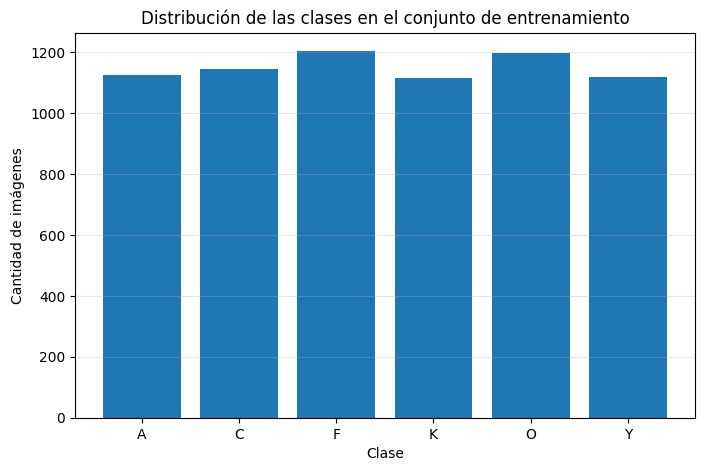

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(
    class_labels,
    train_class_counts.values
)

plt.title("Distribución de las clases en el conjunto de entrenamiento")
plt.xlabel("Clase")
plt.ylabel("Cantidad de imágenes")

plt.grid(axis="y", alpha=0.3)

plt.show()

Comparación porcentual

Porcentajes de representacion de cada clase dentro de nuestro conjunto de entrenamiento.

In [14]:
class_percentages = (
    train_class_counts / train_class_counts.sum() * 100
)

print("Distribución porcentual:\n")

for label, percentage in class_percentages.items():
    print(
        f"{class_names[label]}: {percentage:.2f}%"
    )

Distribución porcentual:

A: 16.31%
C: 16.57%
F: 17.44%
K: 16.14%
O: 17.33%
Y: 16.20%


Visualización de imágenes reales

### Visualización de ejemplos

Aunque el modelo recibirá cada imagen como un conjunto de valores numéricos, resulta importante visualizar las imágenes originales para comprender las diferencias entre las clases.

Cada imagen contiene 784 valores, correspondientes a una matriz de 28 × 28 píxeles en escala de grises.

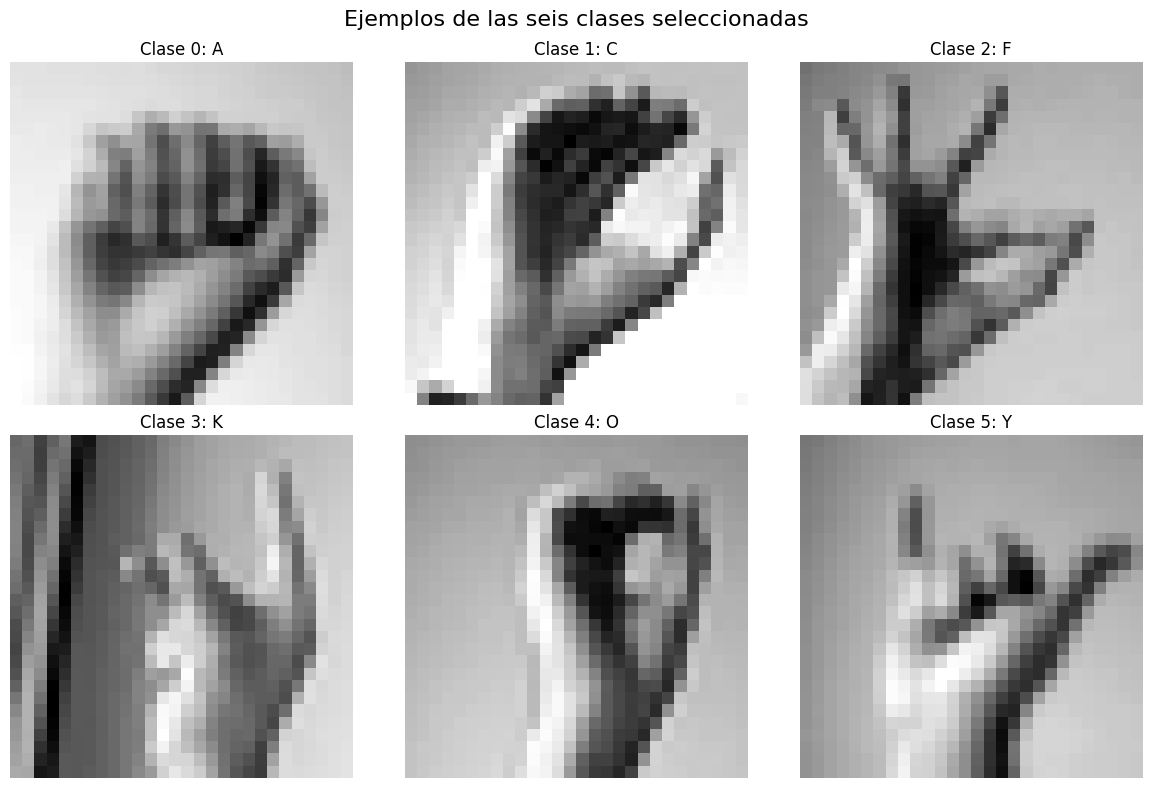

In [15]:
# Creacion de una figura con ejemplos de cada clase seleccionada

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, label in zip(axes.flatten(), sorted(class_names.keys())):

    # Obtener una imagen aleatoria de la clase
    sample = train_filtered[
        train_filtered["label"] == label
    ].sample(1, random_state=SEED)

    # Eliminar la columna label
    image_pixels = sample.drop("label", axis=1).values

    # Convertir los 784 valores nuevamente a 28x28
    image = image_pixels.reshape(28, 28)

    # Mostrar imagen
    ax.imshow(image, cmap="gray")

    ax.set_title(
        f"Clase {label}: {class_names[label]}"
    )

    ax.axis("off")

plt.suptitle(
    "Ejemplos de las seis clases seleccionadas",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Variabilidad visual dentro de cada clase

Además de observar una imagen por clase, se visualizarán múltiples ejemplos.

Esto permitirá identificar variaciones presentes entre las imágenes de una misma categoría y comprender que el modelo no debe memorizar una única imagen, sino aprender patrones generales que permitan reconocer nuevas imágenes.

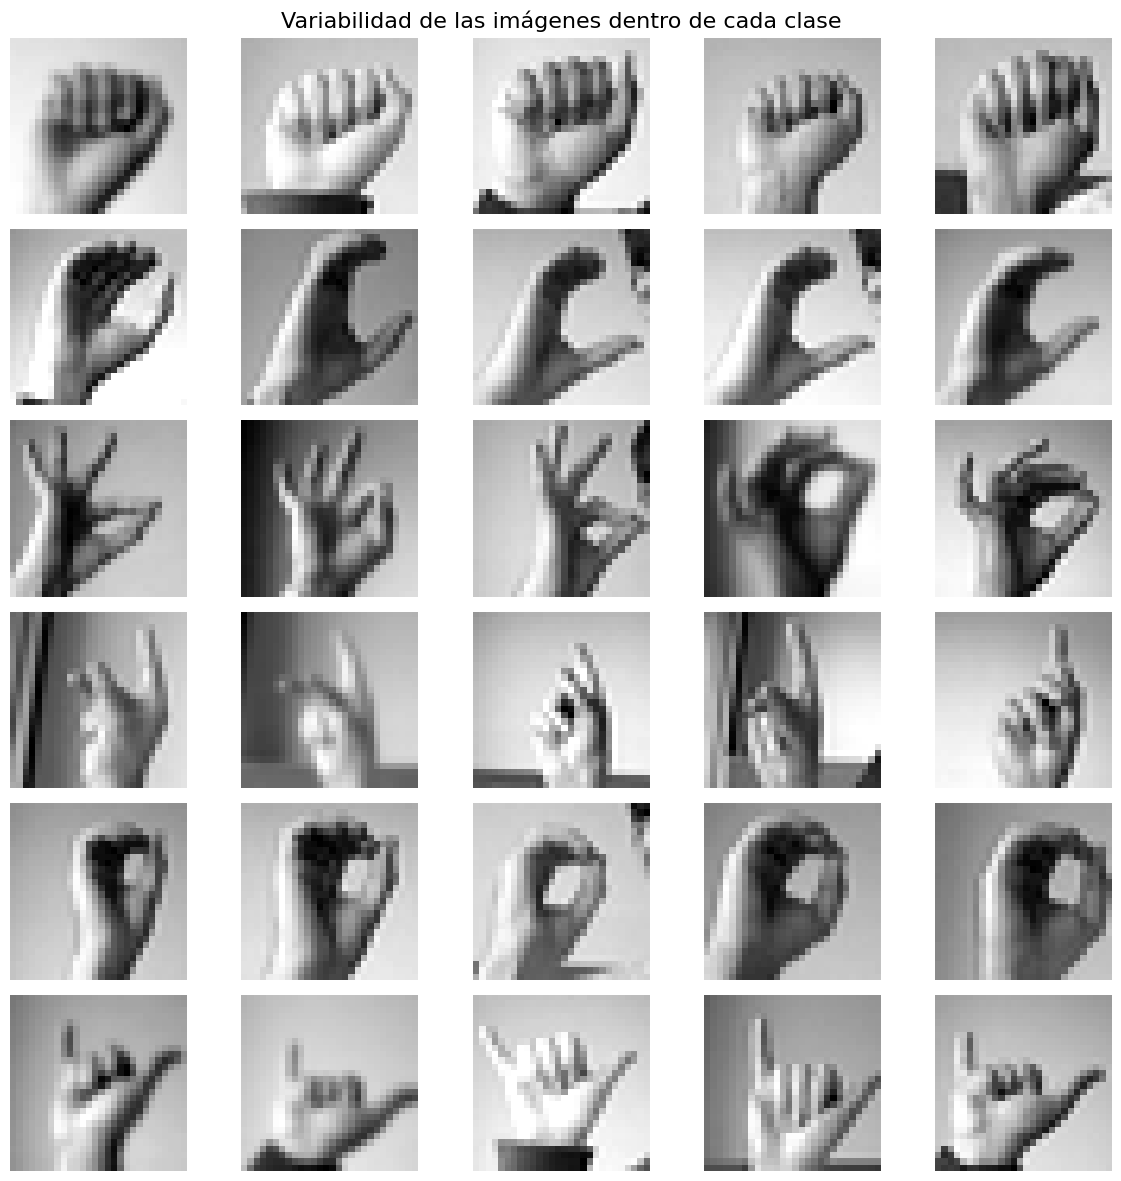

In [16]:
# Número de ejemplos por clase
examples_per_class = 5

# Crear figura
fig, axes = plt.subplots(
    6,
    examples_per_class,
    figsize=(12, 12)
)

for row, label in enumerate(sorted(class_names.keys())):

    # Obtener ejemplos aleatorios de la clase
    samples = train_filtered[
        train_filtered["label"] == label
    ].sample(
        examples_per_class,
        random_state=SEED
    )

    for col, (_, sample) in enumerate(samples.iterrows()):

        # Extraer píxeles
        image = (
            sample
            .drop("label")
            .values
            .reshape(28, 28)
        )

        axes[row, col].imshow(
            image,
            cmap="gray"
        )

        axes[row, col].axis("off")

        # Colocar la letra al comienzo de cada fila
        if col == 0:
            axes[row, col].set_ylabel(
                class_names[label],
                rotation=0,
                labelpad=20,
                fontsize=14,
                fontweight="bold"
            )

plt.suptitle(
    "Variabilidad de las imágenes dentro de cada clase",
    fontsize=16
)

plt.tight_layout()
plt.show()

Analizar los valores de los píxeles

In [17]:
# Separar etiquetas y píxeles temporalmente para el análisis

pixel_columns = [
    col for col in train_filtered.columns
    if col != "label"
]

pixels_train = train_filtered[pixel_columns]

print("Valor mínimo de los píxeles:", pixels_train.min().min())
print("Valor máximo de los píxeles:", pixels_train.max().max())

Valor mínimo de los píxeles: 0
Valor máximo de los píxeles: 255


Distribución de intensidad de los píxeles

### Distribución de los valores de intensidad

Cada píxel de una imagen está representado por un valor numérico que indica su intensidad.

En el dataset original, estos valores se encuentran en un rango aproximado entre 0 y 255.

Posteriormente, estos valores serán normalizados antes del entrenamiento del modelo.

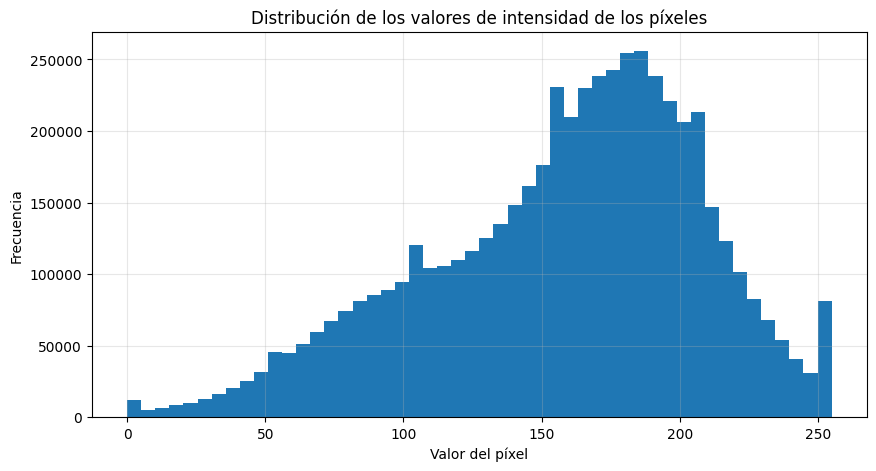

In [18]:
plt.figure(figsize=(10, 5))

plt.hist(
    pixels_train.values.flatten(),
    bins=50
)

plt.title("Distribución de los valores de intensidad de los píxeles")
plt.xlabel("Valor del píxel")
plt.ylabel("Frecuencia")

plt.grid(alpha=0.3)

plt.show()

Visualizacion de una imagen antes y después

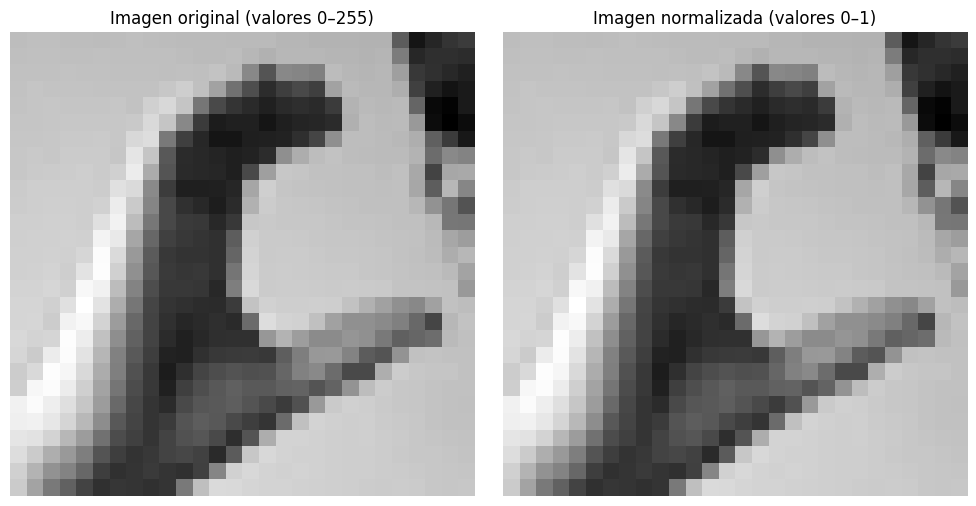

In [19]:
# Seleccionar una imagen de ejemplo
sample_image = train_filtered.iloc[0]

# Obtener los píxeles originales
original_image = (
    sample_image
    .drop("label")
    .values
    .reshape(28, 28)
)

# Normalizar
normalized_image = original_image / 255.0

# Crear comparación visual
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(
    original_image,
    cmap="gray"
)

axes[0].set_title(
    "Imagen original (valores 0–255)"
)

axes[0].axis("off")


axes[1].imshow(
    normalized_image,
    cmap="gray"
)

axes[1].set_title(
    "Imagen normalizada (valores 0–1)"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

## 7. Preparación de los datos

Después de realizar la exploración y selección de las seis clases, se prepararán los datos para el entrenamiento de la red neuronal.

El proceso considera las siguientes etapas:

1. Separación de las características de entrada y las etiquetas.
2. Normalización de los valores de los píxeles.
3. División del conjunto de entrenamiento en datos de entrenamiento y validación.
4. Conservación del conjunto de prueba original para la evaluación final.

Esta división permite evaluar el aprendizaje y la capacidad de generalización del modelo en diferentes etapas del proyecto.

In [20]:
# Separar características y etiquetas del conjunto de entrenamiento

X = train_filtered.drop("label", axis=1)
y = train_filtered["label"]

# Separar características y etiquetas del conjunto de prueba

X_test = test_filtered.drop("label", axis=1)
y_test = test_filtered["label"]

print("Dimensiones de los datos:\n")

print("X:", X.shape)
print("y:", y.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

Dimensiones de los datos:

X: (6902, 784)
y: (6902,)

X_test: (1797, 784)
y_test: (1797,)


## 8. Normalización de las características

Los valores originales de los píxeles se encuentran en un rango de 0 a 255.

Antes del entrenamiento, estos valores serán normalizados dividiendo cada uno por 255. De esta forma, las características de entrada quedarán representadas en un rango entre 0 y 1.

La normalización permite trabajar con una escala numérica más uniforme y facilita el proceso de optimización de la red neuronal.

In [21]:
# Convertir los datos a float32 y normalizar los píxeles

X = X.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Rango de valores después de la normalización:\n")

print(f"Valor mínimo en X: {X.min().min():.4f}")
print(f"Valor máximo en X: {X.max().max():.4f}")

print(f"\nValor mínimo en X_test: {X_test.min().min():.4f}")
print(f"Valor máximo en X_test: {X_test.max().max():.4f}")

Rango de valores después de la normalización:

Valor mínimo en X: 0.0000
Valor máximo en X: 1.0000

Valor mínimo en X_test: 0.0000
Valor máximo en X_test: 1.0000


## 9. División entre entrenamiento y validación

El conjunto de entrenamiento original se dividirá en dos subconjuntos:

- **80 % para entrenamiento:** utilizado para ajustar los parámetros y pesos del modelo.
- **20 % para validación:** utilizado para evaluar el comportamiento del modelo durante el proceso de entrenamiento.

Se utilizará una división estratificada para mantener una proporción similar de cada una de las seis clases en ambos conjuntos.

In [22]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Dimensiones después de la división:\n")

print("Entrenamiento:")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")

print("\nValidación:")
print(f"X_val: {X_val.shape}")
print(f"y_val: {y_val.shape}")

print("\nPrueba:")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

Dimensiones después de la división:

Entrenamiento:
X_train: (5521, 784)
y_train: (5521,)

Validación:
X_val: (1381, 784)
y_val: (1381,)

Prueba:
X_test: (1797, 784)
y_test: (1797,)


Verificar la distribución después de dividir

In [23]:
# Distribución porcentual de las clases

train_distribution = (
    y_train
    .value_counts(normalize=True)
    .sort_index() * 100
)

val_distribution = (
    y_val
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Distribución porcentual por clase:\n")

distribution_df = pd.DataFrame({
    "Entrenamiento (%)": train_distribution,
    "Validación (%)": val_distribution
})

# Reemplazar índices por nombres de letras
distribution_df.index = [
    class_names[label]
    for label in distribution_df.index
]

distribution_df

Distribución porcentual por clase:



,Entrenamiento (%),Validación (%)
A,16.319507,16.292542
C,16.573085,16.582187
F,17.442492,17.451122
K,16.138381,16.147719
O,17.333816,17.306300
Y,16.192719,16.220130


Resumen final de nuestros conjuntos

In [24]:
data_summary = pd.DataFrame({
    "Conjunto": [
        "Entrenamiento",
        "Validación",
        "Prueba"
    ],
    "Cantidad de imágenes": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Uso": [
        "Aprendizaje de los pesos",
        "Monitoreo durante el entrenamiento",
        "Evaluación final"
    ]
})

data_summary

,Conjunto,Cantidad de imágenes,Uso
0,Entrenamiento,5521,Aprendizaje de los pesos
1,Validación,1381,Monitoreo durante el entrenamiento
2,Prueba,1797,Evaluación final


## 10. Construcción del MLP

Se construye la red neuronal tipo Perceptrón Multicapa con la arquitectura definida en la introducción:

784 características de entrada → primera capa con 128 neuronas con activación ReLU → segunda capa con 64 neuronas con activación ReLU → 6 neuronas de salida con activación Softmax

Antes de construir la red se definen las cantidades `M` (ejemplos), `N` (neuronas de entrada) y `C` (neuronas de salida) directamente a partir de los datos, de manera que la red quede acoplada al conjunto realmente preparado en los puntos anteriores.

In [25]:
# 1. Cantidad de ejemplos, neuronas de entrada y neuronas de salida

M = X_train.shape[0]      # Cantidad de imágenes de entrenamiento
N = X_train.shape[1]      # Píxeles aplanados (28 x 28 = 784)
C = len(class_names)      # Nuestras 6 clases / letras finales

print("M (ejemplos de entrenamiento):", M)
print("N (neuronas de entrada):", N)
print("C (neuronas de salida):", C)

# 2. Tamaños de las capas escondidas

h1 = 128  # Neuronas en la primera capa oculta
h2 = 64   # Neuronas en la segunda capa oculta

# 3. Construcción de la red feed-forward

red = keras.Sequential(name="Red_Lenguaje_de_Senas")
red.add(keras.Input(shape=(N,)))
red.add(keras.layers.Dense(h1, activation='relu', name='primera_capa'))
red.add(keras.layers.Dense(h2, activation='relu', name='segunda_capa'))
red.add(keras.layers.Dense(C, activation='softmax', name='capa_de_salida'))

# 4. Resumen de la arquitectura y de los parámetros
red.summary()

M (ejemplos de entrenamiento): 5521
N (neuronas de entrada): 784
C (neuronas de salida): 6


Model: "Red_Lenguaje_de_Senas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ primera_capa (Dense)            │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ segunda_capa (Dense)            │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_de_salida (Dense)          │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,126 (426.27 KB)

 Trainable params: 109,126 (426.27 KB)

 Non-trainable params: 0 (0.00 B)

**¿Cómo se calcula la cantidad de parámetros de cada capa?**

---

+ Para la primera capa: $100480 = 784 * 128 + 128$
+ Para la segunda capa: $8256 = 128 * 64 + 64$
+ Para la capa de salida: $390 = 64 * 6 + 6$

En total la red tiene $109126$ parámetros entrenables (pesos + sesgos).

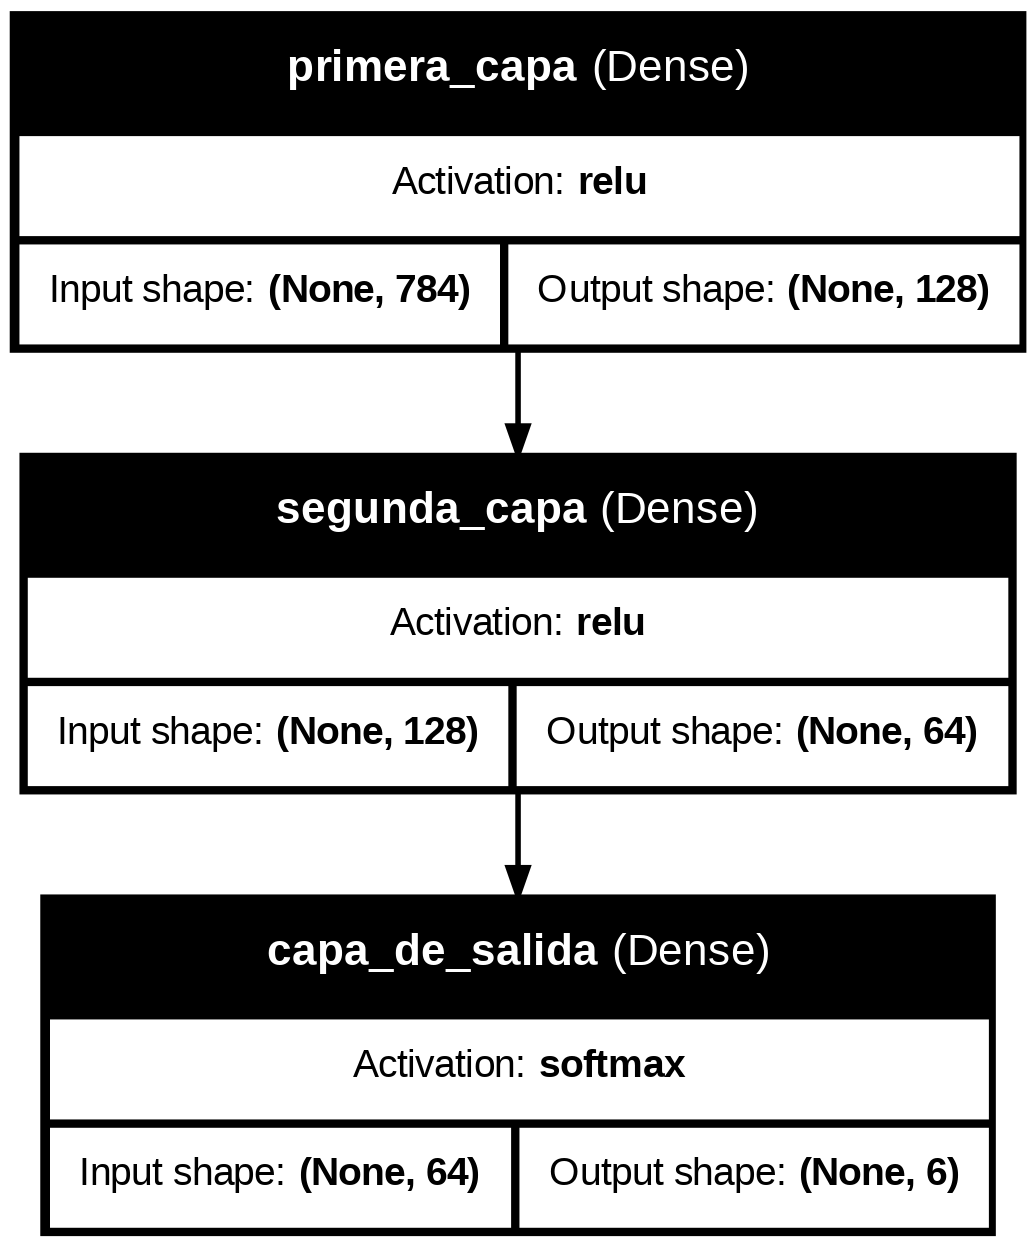

In [26]:
# 5. Generar y mostrar el diagrama de la red

try:
    plot_model(
        red,
        to_file='red_plot.png',
        show_shapes=True,
        show_layer_names=True,
        show_layer_activations=True
    )
    display(Image('red_plot.png'))
except Exception as e:
    print("No fue posible generar el diagrama (requiere pydot y graphviz):", e)

## 11. Compilación y entrenamiento

### Compilación de la red

Antes de entrenar, la red debe **compilarse** con `.compile`. En esta etapa se define:

+ La **pérdida** (`loss`): se utiliza `sparse_categorical_crossentropy`, que es la versión de la entropía cruzada categórica para etiquetas enteras. Como las clases fueron recodificadas a los valores 0, 1, 2, 3, 4 y 5, no es necesario transformarlas a formato one-hot.
+ El **algoritmo de optimización** (`optimizer`): se utiliza `adam`, que ajusta automáticamente la tasa de aprendizaje de cada parámetro y converge más rápido que `sgd` sin momentum.
+ Las **métricas** (`metrics`): se agrega `accuracy` para monitorear el porcentaje de acierto durante el entrenamiento.

### Entrenamiento de la red

El entrenamiento se realiza con `.fit`, entregando las entradas y las etiquetas. Además se definen:

+ La cantidad de **épocas** (`epochs`): 20 pasadas completas sobre el conjunto de entrenamiento.
+ El **tamaño del paquete** (`batch_size`): 32 imágenes por lote. Un `batch_size` de 1 resulta demasiado lento para este volumen de datos.
+ Los **datos de validación** (`validation_data`): se entrega explícitamente el conjunto de validación creado en el punto 9, en lugar de usar `validation_split`, para que la validación mantenga la división estratificada ya realizada.

El objeto devuelto por `.fit` se guarda en la variable `h`, que contiene el historial de las métricas de cada época y será analizado en el punto 12.

In [27]:
# 1. Compilación de la red

red.compile(
    loss='sparse_categorical_crossentropy',   # etiquetas enteras de 0 a 5
    optimizer='adam',                         # mejor convergencia que 'sgd' sin momentum
    metrics=['accuracy']
)

print("Red compilada correctamente.")

Red compilada correctamente.


In [28]:
# 2. Entrenamiento de la red, registrando el tiempo

EPOCAS = 20
BATCH_SIZE = 32

start_time = time()

h = red.fit(
    X_train,                          # Imágenes de entrenamiento normalizadas (784 columnas)
    y_train,                          # Etiquetas recodificadas de 0 a 5
    epochs=EPOCAS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),   # Conjunto de validación del punto 9
    verbose=1
)

end_time = time()

print("\nTiempo de entrenamiento: %0.4f segundos" % (end_time - start_time))

Epoch 1/20
173/173 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.6772 - loss: 0.9079 - val_accuracy: 0.8841 - val_loss: 0.4428
Epoch 2/20
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9026 - loss: 0.3388 - val_accuracy: 0.9211 - val_loss: 0.2472
Epoch 3/20
173/173 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9489 - loss: 0.1905 - val_accuracy: 0.9718 - val_loss: 0.1397
Epoch 4/20
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9688 - loss: 0.1195 - val_accuracy: 0.9862 - val_loss: 0.0765
Epoch 5/20
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9801 - loss: 0.0839 - val_accuracy: 0.9949 - val_loss: 0.0452
Epoch 6/20
173/173 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9909 - loss: 0.0492 - val_accuracy: 1.0000 - val_loss: 0.0307
Epoch 7/20
173/173 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9944 - loss: 0.0342 - val_accuracy: 1.0000 - val_loss: 0.0218
Epoch 8/20
173/173 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9980 - loss: 0.0207 - val_accuracy

## 12. Análisis de Loss y Accuracy

Durante el entrenamiento se registraron cuatro métricas en cada época:

- **Loss:** error del modelo sobre los datos de entrenamiento.
- **Validation Loss:** error del modelo sobre los datos de validación.
- **Accuracy:** porcentaje de acierto sobre los datos de entrenamiento.
- **Validation Accuracy:** porcentaje de acierto sobre los datos de validación.

Comparar las curvas de entrenamiento con las de validación permite observar cómo aprende la red y detectar problemas:

- Si ambas curvas mejoran juntas, el modelo está aprendiendo patrones generales.
- Si la pérdida de entrenamiento sigue bajando mientras la de validación sube, existe **sobreajuste** (overfitting): el modelo memoriza los datos de entrenamiento.
- Si ninguna de las dos alcanza un buen desempeño, existe **subajuste** (underfitting): la red es insuficiente para el problema.

In [29]:
# Métricas registradas por Keras en cada época
print("Métricas disponibles en el historial:")
print(list(h.history.keys()))

Métricas disponibles en el historial:
['accuracy', 'loss', 'val_accuracy', 'val_loss']


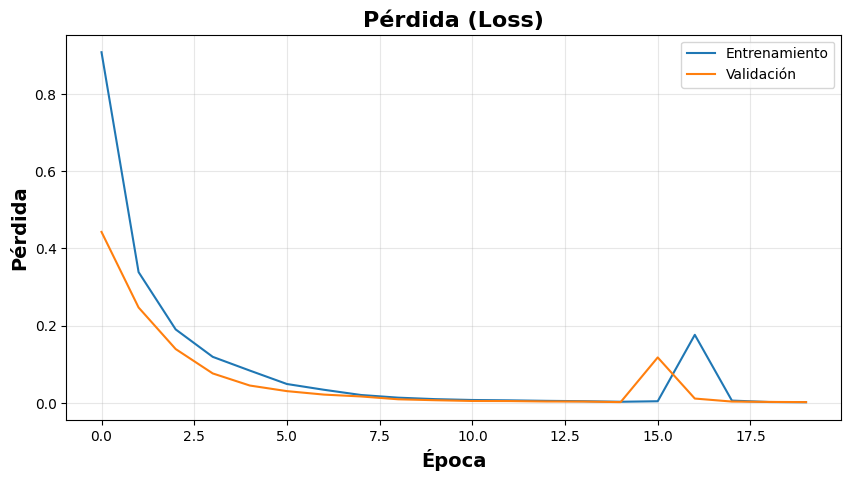

In [30]:
# Gráfica de la pérdida para cada época

plt.figure(figsize=(10, 5))

plt.plot(h.history['loss'], label='Entrenamiento')
plt.plot(h.history['val_loss'], label='Validación')

plt.title('Pérdida (Loss)', fontsize=16, fontweight="bold")
plt.xlabel('Época', fontsize=14, fontweight="bold")
plt.ylabel('Pérdida', fontsize=14, fontweight="bold")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

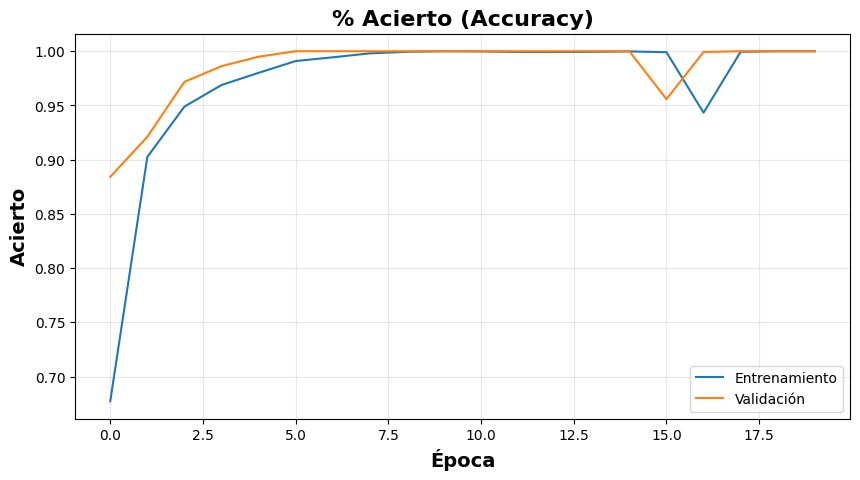

In [31]:
# Gráfica del porcentaje de acierto para cada época

plt.figure(figsize=(10, 5))

plt.plot(h.history['accuracy'], label='Entrenamiento')
plt.plot(h.history['val_accuracy'], label='Validación')

plt.title('% Acierto (Accuracy)', fontsize=16, fontweight="bold")
plt.xlabel('Época', fontsize=14, fontweight="bold")
plt.ylabel('Acierto', fontsize=14, fontweight="bold")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 12.1 Resumen numérico del entrenamiento

Además de las curvas, se revisan los valores obtenidos en la primera y en la última época, junto con la diferencia entre entrenamiento y validación. Una brecha grande entre ambos valores es un indicio de sobreajuste.

In [32]:
# Tabla comparativa entre la primera y la última época

historial = pd.DataFrame(h.history)
historial.index = range(1, len(historial) + 1)
historial.index.name = "Época"

resumen_entrenamiento = pd.DataFrame({
    "Primera época": historial.iloc[0],
    "Última época": historial.iloc[-1]
})

print("Evolución de las métricas:\n")
display(resumen_entrenamiento.round(4))

brecha_acc = historial['accuracy'].iloc[-1] - historial['val_accuracy'].iloc[-1]
brecha_loss = historial['val_loss'].iloc[-1] - historial['loss'].iloc[-1]

print(f"\nBrecha de accuracy (entrenamiento - validación): {brecha_acc:.4f}")
print(f"Brecha de loss (validación - entrenamiento): {brecha_loss:.4f}")

mejor_epoca = int(historial['val_loss'].idxmin())
print(f"\nÉpoca con menor pérdida de validación: {mejor_epoca}")
print(f"Val_loss en esa época: {historial['val_loss'].min():.4f}")
print(f"Val_accuracy en esa época: {historial.loc[mejor_epoca, 'val_accuracy']:.4f}")

Evolución de las métricas:



,Primera época,Última época
accuracy,0.6772,1.0000
loss,0.9079,0.0020
val_accuracy,0.8841,1.0000
val_loss,0.4428,0.0023



Brecha de accuracy (entrenamiento - validación): 0.0000
Brecha de loss (validación - entrenamiento): 0.0003

Época con menor pérdida de validación: 15
Val_loss en esa época: 0.0023
Val_accuracy en esa época: 1.0000


In [33]:
# Historial completo por época

display(historial.round(4))

,accuracy,loss,val_accuracy,val_loss
Época,,,,
1,0.6772,0.9079,0.8841,0.4428
2,0.9026,0.3388,0.9211,0.2472
3,0.9489,0.1905,0.9718,0.1397
4,0.9688,0.1195,0.9862,0.0765
5,0.9801,0.0839,0.9949,0.0452
6,0.9909,0.0492,1.0000,0.0307
7,0.9944,0.0342,1.0000,0.0218
8,0.9980,0.0207,1.0000,0.0169
9,0.9995,0.0138,1.0000,0.0096


## 13. Evaluación final

Las métricas anteriores fueron calculadas sobre los conjuntos de entrenamiento y validación, ambos derivados del archivo original de entrenamiento.

Para estimar la capacidad real de generalización del modelo se utiliza ahora el **conjunto de prueba**, que fue reservado desde el comienzo y que la red nunca vio durante el entrenamiento.

Se calculan:

- **Accuracy:** proporción de imágenes clasificadas correctamente.
- **Precision:** de todo lo que el modelo predijo como una clase, cuánto era realmente de esa clase.
- **Recall:** de todas las imágenes reales de una clase, cuántas fue capaz de encontrar el modelo.
- **F1-score:** media armónica entre precision y recall.

Las métricas se presentan en promedio **macro** (todas las clases pesan igual) y **weighted** (ponderado por la cantidad de imágenes de cada clase).

In [34]:
# Evaluación directa con Keras sobre el conjunto de prueba

test_loss, test_accuracy = red.evaluate(X_test, y_test, verbose=0)

print("Resultados sobre el conjunto de prueba:\n")
print(f"Pérdida (loss): {test_loss:.4f}")
print(f"Acierto (accuracy): {test_accuracy:.4f}  ({test_accuracy * 100:.2f} %)")

Resultados sobre el conjunto de prueba:

Pérdida (loss): 0.5159
Acierto (accuracy): 0.8703  (87.03 %)


In [35]:
# Predicciones del modelo sobre el conjunto de prueba

y_pred_proba = red.predict(X_test, verbose=0)   # Probabilidades de cada una de las 6 clases
y_pred = np.argmax(y_pred_proba, axis=1)        # Clase con mayor probabilidad
y_true = np.array(y_test)                       # Etiquetas reales

print("Forma de las probabilidades predichas:", y_pred_proba.shape)
print("Forma de las clases predichas:", y_pred.shape)

print("\nPrimeras 10 predicciones:")
for i in range(10):
    print(
        f"Imagen {i}: real = {class_names[y_true[i]]}, "
        f"predicho = {class_names[y_pred[i]]}, "
        f"confianza = {y_pred_proba[i].max():.4f}"
    )

Forma de las probabilidades predichas: (1797, 6)
Forma de las clases predichas: (1797,)

Primeras 10 predicciones:
Imagen 0: real = F, predicho = F, confianza = 0.9988
Imagen 1: real = K, predicho = K, confianza = 0.9997
Imagen 2: real = A, predicho = A, confianza = 1.0000
Imagen 3: real = K, predicho = K, confianza = 0.9658
Imagen 4: real = O, predicho = O, confianza = 0.9992
Imagen 5: real = A, predicho = A, confianza = 0.9985
Imagen 6: real = C, predicho = C, confianza = 1.0000
Imagen 7: real = A, predicho = A, confianza = 1.0000
Imagen 8: real = K, predicho = K, confianza = 0.9846
Imagen 9: real = C, predicho = C, confianza = 0.7158


In [36]:
# Métricas de clasificación

accuracy = accuracy_score(y_true, y_pred)

metricas = pd.DataFrame({
    "Macro": [
        precision_score(y_true, y_pred, average="macro"),
        recall_score(y_true, y_pred, average="macro"),
        f1_score(y_true, y_pred, average="macro")
    ],
    "Weighted": [
        precision_score(y_true, y_pred, average="weighted"),
        recall_score(y_true, y_pred, average="weighted"),
        f1_score(y_true, y_pred, average="weighted")
    ]
}, index=["Precision", "Recall", "F1-score"])

print(f"Accuracy global: {accuracy:.4f}  ({accuracy * 100:.2f} %)\n")
display(metricas.round(4))

Accuracy global: 0.8703  (87.03 %)



,Macro,Weighted
Precision,0.8778,0.8785
Recall,0.8698,0.8703
F1-score,0.8694,0.8707


### 13.1 Reporte por clase

El reporte de clasificación entrega precision, recall y F1-score de forma individual para cada una de las seis letras, junto con el **support** (cantidad de imágenes reales de esa clase en el conjunto de prueba). Esto permite identificar si el modelo tiene un desempeño desigual entre las clases.

In [37]:
# Reporte de clasificación por clase

nombres_clases = [class_names[i] for i in sorted(class_names.keys())]

print("Reporte de clasificación:\n")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=nombres_clases,
        digits=4
    )
)

Reporte de clasificación:

              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       331
           C     0.9325    0.9806    0.9560       310
           F     0.7244    0.9150    0.8086       247
           K     0.8487    0.7795    0.8126       331
           O     1.0000    0.7846    0.8793       246
           Y     0.7613    0.7590    0.7602       332

    accuracy                         0.8703      1797
   macro avg     0.8778    0.8698    0.8694      1797
weighted avg     0.8785    0.8703    0.8707      1797



In [38]:
# El mismo reporte en formato de tabla, para comparar clases con mayor comodidad

reporte = classification_report(
    y_true,
    y_pred,
    target_names=nombres_clases,
    output_dict=True
)

reporte_df = pd.DataFrame(reporte).transpose()

display(reporte_df.round(4))

,precision,recall,f1-score,support
A,1.0000,1.0000,1.0000,331.0000
C,0.9325,0.9806,0.9560,310.0000
F,0.7244,0.9150,0.8086,247.0000
K,0.8487,0.7795,0.8126,331.0000
O,1.0000,0.7846,0.8793,246.0000
Y,0.7613,0.7590,0.7602,332.0000
accuracy,0.8703,0.8703,0.8703,0.8703
macro avg,0.8778,0.8698,0.8694,1797.0000
weighted avg,0.8785,0.8703,0.8707,1797.0000


## 14. Matriz de confusión

La matriz de confusión muestra, para cada clase real (filas), cómo fueron distribuidas las predicciones del modelo (columnas).

- Los valores de la **diagonal** corresponden a las imágenes clasificadas correctamente.
- Los valores **fuera de la diagonal** corresponden a las confusiones: qué letra fue confundida con qué otra.

Esta visualización es especialmente útil en lenguaje de señas, porque permite verificar si el modelo confunde configuraciones manuales visualmente parecidas entre sí.

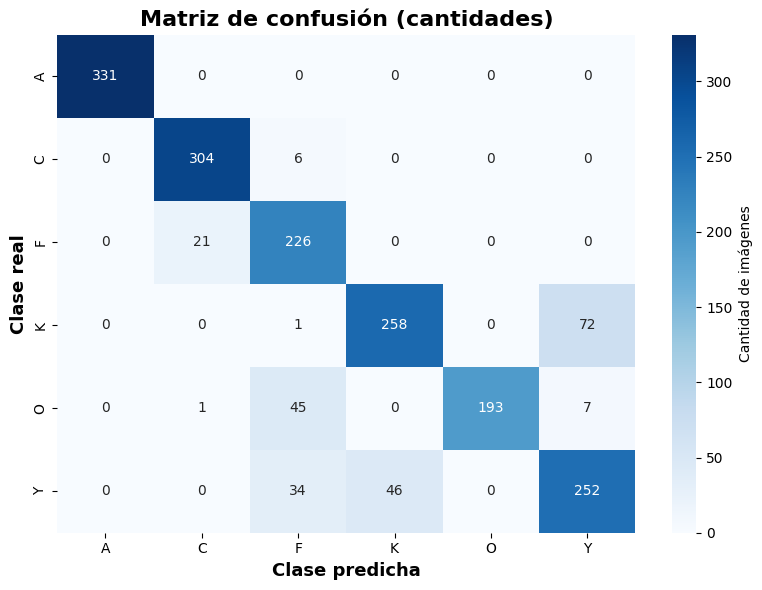

In [39]:
# Matriz de confusión en cantidad de imágenes

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases,
    cbar_kws={"label": "Cantidad de imágenes"}
)

plt.title("Matriz de confusión (cantidades)", fontsize=16, fontweight="bold")
plt.xlabel("Clase predicha", fontsize=13, fontweight="bold")
plt.ylabel("Clase real", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

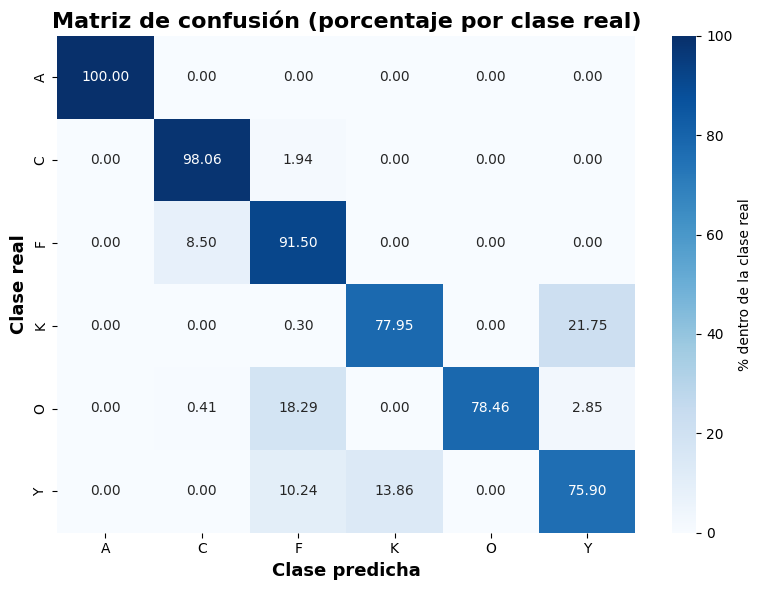

In [40]:
# Matriz de confusión normalizada por fila (porcentaje dentro de cada clase real)

cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True) * 100

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases,
    vmin=0,
    vmax=100,
    cbar_kws={"label": "% dentro de la clase real"}
)

plt.title("Matriz de confusión (porcentaje por clase real)", fontsize=16, fontweight="bold")
plt.xlabel("Clase predicha", fontsize=13, fontweight="bold")
plt.ylabel("Clase real", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

In [41]:
# Confusiones más frecuentes fuera de la diagonal

confusiones = []

for i in sorted(class_names.keys()):
    for j in sorted(class_names.keys()):
        if i != j and cm[i, j] > 0:
            confusiones.append({
                "Clase real": class_names[i],
                "Clase predicha": class_names[j],
                "Cantidad": int(cm[i, j]),
                "% de la clase real": round(cm[i, j] / cm[i].sum() * 100, 2)
            })

if len(confusiones) == 0:
    print("No se registraron confusiones: todas las imágenes de prueba fueron clasificadas correctamente.")
else:
    confusiones_df = (
        pd.DataFrame(confusiones)
        .sort_values("Cantidad", ascending=False)
        .reset_index(drop=True)
    )
    print("Confusiones ordenadas de mayor a menor:\n")
    display(confusiones_df)

Confusiones ordenadas de mayor a menor:



,Clase real,Clase predicha,Cantidad,% de la clase real
0,K,Y,72,21.75
1,Y,K,46,13.86
2,O,F,45,18.29
3,Y,F,34,10.24
4,F,C,21,8.50
5,O,Y,7,2.85
6,C,F,6,1.94
7,O,C,1,0.41
8,K,F,1,0.30


## 15. Análisis de errores

Además de conocer cuántos errores comete el modelo, resulta importante observar **cuáles** son esas imágenes y **con qué seguridad** el modelo se equivoca.

En esta sección se revisan:

1. La cantidad y la tasa de error por clase.
2. Una grilla con predicciones sobre imágenes de prueba tomadas al azar.
3. Una grilla con las imágenes mal clasificadas.
4. La confianza del modelo en los aciertos frente a los errores.

In [42]:
# Cantidad de errores y tasa de error por clase

errores_mask = (y_pred != y_true)
total_errores = int(errores_mask.sum())

print(f"Total de imágenes de prueba: {len(y_true)}")
print(f"Imágenes clasificadas correctamente: {len(y_true) - total_errores}")
print(f"Imágenes mal clasificadas: {total_errores}")
print(f"Tasa de error global: {total_errores / len(y_true) * 100:.2f} %")

errores_por_clase = []

for label in sorted(class_names.keys()):
    mask_clase = (y_true == label)
    total_clase = int(mask_clase.sum())
    errores_clase = int((y_pred[mask_clase] != label).sum())

    errores_por_clase.append({
        "Clase": class_names[label],
        "Imágenes de prueba": total_clase,
        "Errores": errores_clase,
        "Tasa de error (%)": round(errores_clase / total_clase * 100, 2) if total_clase else 0.0
    })

errores_df = pd.DataFrame(errores_por_clase).sort_values("Tasa de error (%)", ascending=False)

print("\nErrores por clase:\n")
display(errores_df.reset_index(drop=True))

Total de imágenes de prueba: 1797
Imágenes clasificadas correctamente: 1564
Imágenes mal clasificadas: 233
Tasa de error global: 12.97 %

Errores por clase:



,Clase,Imágenes de prueba,Errores,Tasa de error (%)
0,Y,332,80,24.10
1,K,331,73,22.05
2,O,246,53,21.54
3,F,247,21,8.50
4,C,310,6,1.94
5,A,331,0,0.00


### 15.1 Grilla de predicciones

Se muestra una grilla con imágenes de prueba tomadas al azar, indicando la etiqueta real y la predicha por la red. Los títulos en verde corresponden a aciertos y los títulos en rojo a errores.

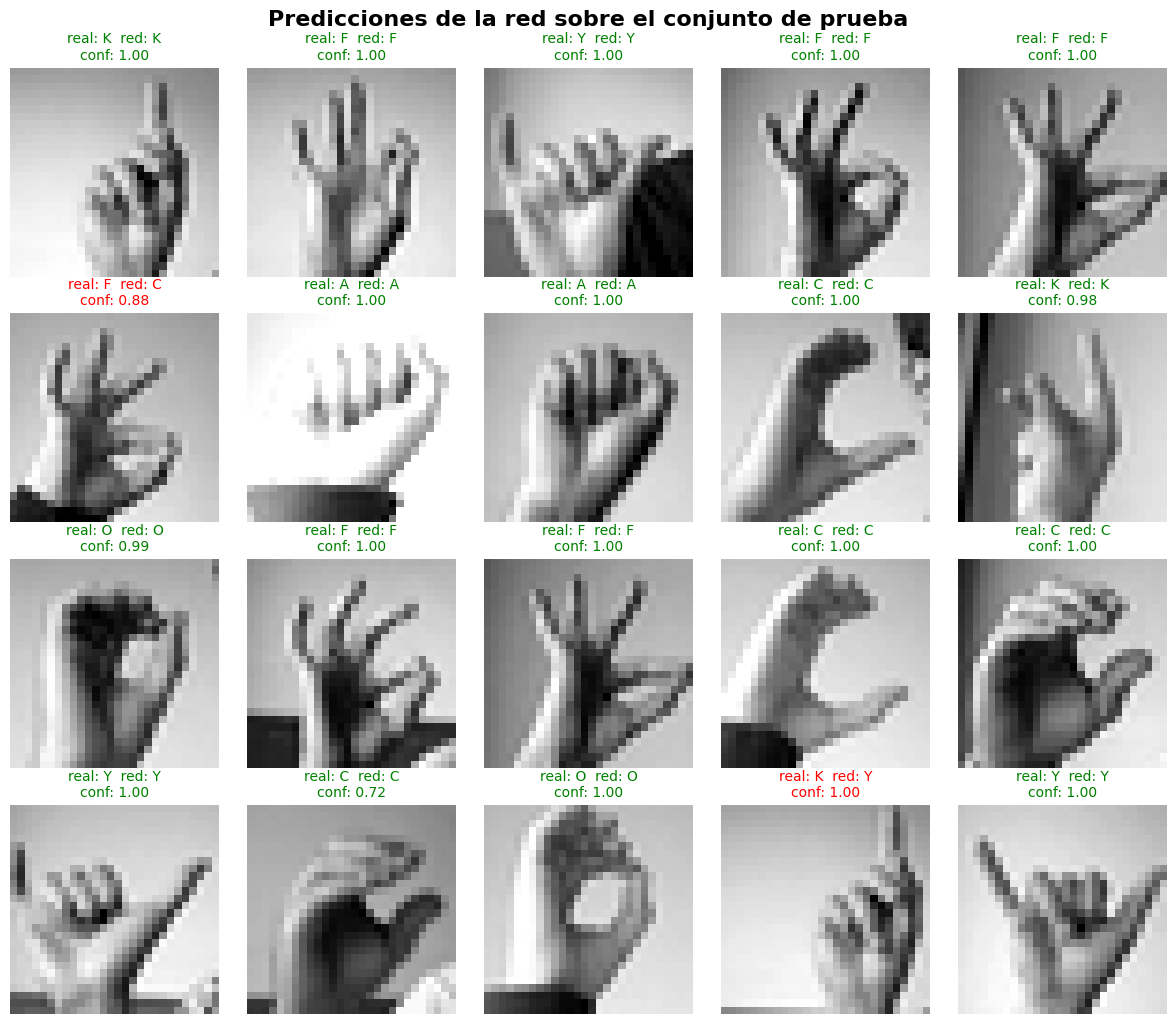

In [43]:
# Grilla de predicciones sobre imágenes de prueba al azar

alto = 4
ancho = 5

indices = np.random.choice(len(y_true), alto * ancho, replace=False)

fig, axs = plt.subplots(alto, ancho, figsize=(2.4 * ancho, 2.6 * alto))

for k, ex in enumerate(indices):
    i, j = divmod(k, ancho)

    imagen = X_test.iloc[ex].values.reshape(28, 28)
    real = class_names[y_true[ex]]
    predicho = class_names[y_pred[ex]]
    confianza = y_pred_proba[ex].max()

    color = "green" if y_true[ex] == y_pred[ex] else "red"

    axs[i, j].imshow(imagen, cmap="gray")
    axs[i, j].set_title(
        f"real: {real}  red: {predicho}\nconf: {confianza:.2f}",
        fontsize=10,
        color=color
    )
    axs[i, j].axis("off")

plt.suptitle("Predicciones de la red sobre el conjunto de prueba", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### 15.2 Imágenes mal clasificadas

A continuación se visualizan únicamente los casos en que el modelo se equivocó. Observar estas imágenes permite entender si los errores se deben a configuraciones manuales parecidas, a diferencias de iluminación o a imágenes poco nítidas.

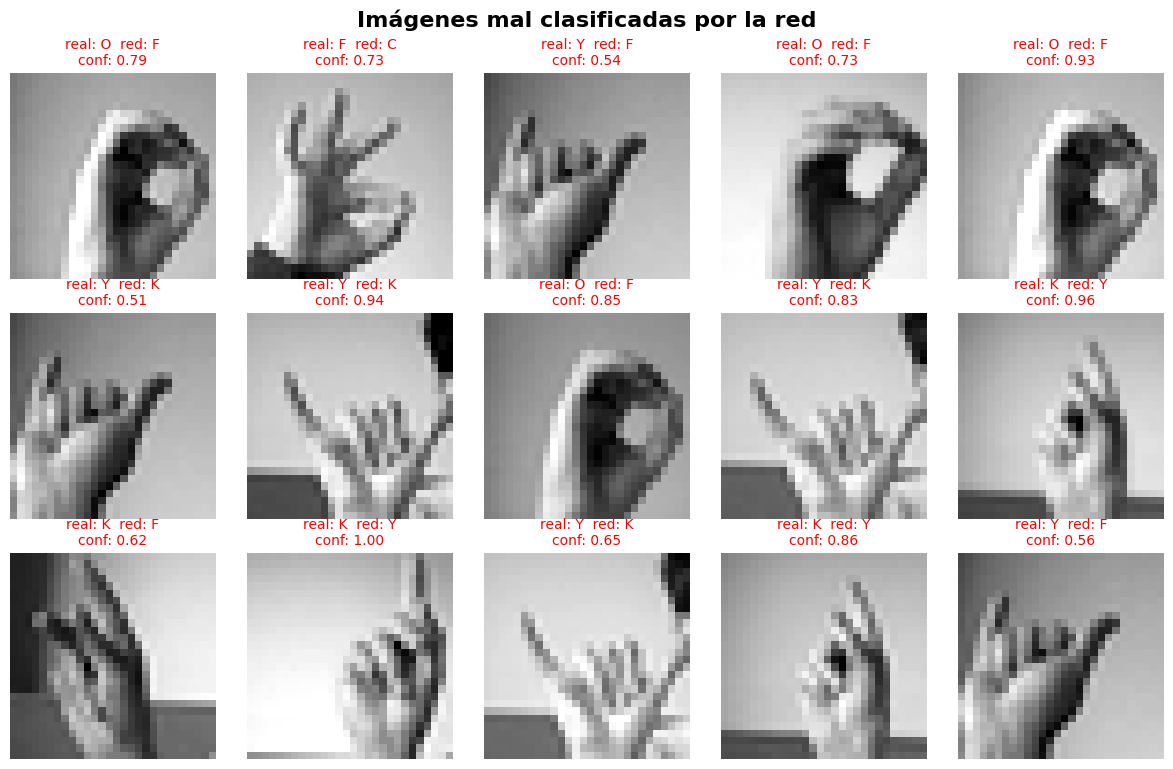

In [44]:
# Grilla con las imágenes mal clasificadas

indices_errores = np.where(errores_mask)[0]

if len(indices_errores) == 0:
    print("El modelo no cometió errores sobre el conjunto de prueba, por lo que no hay imágenes que mostrar.")
else:
    cantidad = min(15, len(indices_errores))
    seleccion = np.random.choice(indices_errores, cantidad, replace=False)

    columnas = 5
    filas = int(np.ceil(cantidad / columnas))

    fig, axs = plt.subplots(filas, columnas, figsize=(2.4 * columnas, 2.6 * filas))
    axs = np.array(axs).reshape(-1)

    for k, ex in enumerate(seleccion):
        imagen = X_test.iloc[ex].values.reshape(28, 28)

        axs[k].imshow(imagen, cmap="gray")
        axs[k].set_title(
            f"real: {class_names[y_true[ex]]}  red: {class_names[y_pred[ex]]}\n"
            f"conf: {y_pred_proba[ex].max():.2f}",
            fontsize=10,
            color="red"
        )
        axs[k].axis("off")

    # Apagar los ejes sobrantes
    for k in range(cantidad, len(axs)):
        axs[k].axis("off")

    plt.suptitle("Imágenes mal clasificadas por la red", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

### 15.3 Confianza del modelo en aciertos y errores

La capa de salida Softmax entrega una probabilidad para cada clase. La mayor de esas probabilidades se interpreta como la **confianza** del modelo en su predicción.

Un modelo bien calibrado debería mostrar una confianza alta en los aciertos y una confianza menor en los errores. Si el modelo se equivoca con confianza muy alta, significa que está muy seguro de predicciones incorrectas, lo que es un comportamiento más riesgoso.

Confianza promedio en los aciertos: 0.9665
Confianza promedio en los errores: 0.7541


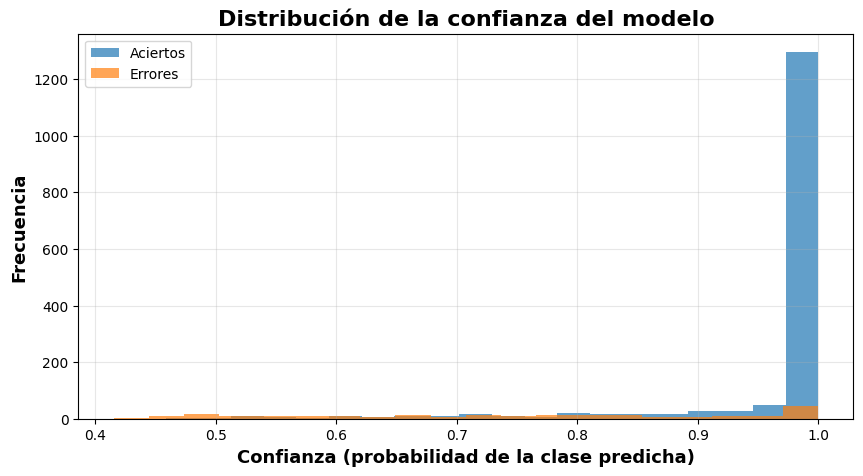

In [45]:
# Comparación de la confianza en aciertos y en errores

confianzas = y_pred_proba.max(axis=1)

confianza_aciertos = confianzas[~errores_mask]
confianza_errores = confianzas[errores_mask]

print(f"Confianza promedio en los aciertos: {confianza_aciertos.mean():.4f}")

if len(confianza_errores) > 0:
    print(f"Confianza promedio en los errores: {confianza_errores.mean():.4f}")
else:
    print("Confianza promedio en los errores: no aplica (no hubo errores)")

plt.figure(figsize=(10, 5))

plt.hist(confianza_aciertos, bins=20, alpha=0.7, label="Aciertos")

if len(confianza_errores) > 0:
    plt.hist(confianza_errores, bins=20, alpha=0.7, label="Errores")

plt.title("Distribución de la confianza del modelo", fontsize=16, fontweight="bold")
plt.xlabel("Confianza (probabilidad de la clase predicha)", fontsize=13, fontweight="bold")
plt.ylabel("Frecuencia", fontsize=13, fontweight="bold")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 16. Conclusiones

In [46]:
# Resumen final del proyecto con los valores obtenidos

resumen_final = pd.DataFrame({
    "Aspecto": [
        "Dataset",
        "Clases seleccionadas",
        "Imágenes de entrenamiento",
        "Imágenes de validación",
        "Imágenes de prueba",
        "Arquitectura",
        "Parámetros entrenables",
        "Función de pérdida",
        "Optimizador",
        "Épocas",
        "Batch size",
        "Accuracy de entrenamiento (última época)",
        "Accuracy de validación (última época)",
        "Accuracy de prueba",
        "F1-score macro (prueba)",
        "Imágenes mal clasificadas (prueba)"
    ],
    "Valor": [
        "Sign Language MNIST",
        ", ".join(nombres_clases),
        len(X_train),
        len(X_val),
        len(X_test),
        f"{N} - {h1} (ReLU) - {h2} (ReLU) - {C} (Softmax)",
        red.count_params(),
        "sparse_categorical_crossentropy",
        "adam",
        EPOCAS,
        BATCH_SIZE,
        f"{historial['accuracy'].iloc[-1] * 100:.2f} %",
        f"{historial['val_accuracy'].iloc[-1] * 100:.2f} %",
        f"{accuracy * 100:.2f} %",
        f"{f1_score(y_true, y_pred, average='macro'):.4f}",
        f"{total_errores} de {len(y_true)}"
    ]
})

display(resumen_final)

,Aspecto,Valor
0,Dataset,Sign Language MNIST
1,Clases seleccionadas,"A, C, F, K, O, Y"
2,Imágenes de entrenamiento,5521
3,Imágenes de validación,1381
4,Imágenes de prueba,1797
5,Arquitectura,784 - 128 (ReLU) - 64 (ReLU) - 6 (Softmax)
6,Parámetros entrenables,109126
7,Función de pérdida,sparse_categorical_crossentropy
8,Optimizador,adam
9,Épocas,20


### Conclusiones del proyecto

**Sobre el problema y los datos**

Se construyó una variante de seis clases (A, C, F, K, O, Y) a partir del dataset Sign Language MNIST. La exploración inicial mostró que el conjunto no presenta valores faltantes y que las seis clases seleccionadas están razonablemente equilibradas, por lo que el accuracy es una métrica representativa y no se requirieron técnicas de balanceo.

**Sobre la preparación de los datos**

Cada imagen fue tratada como un vector de 784 características. La normalización de los píxeles al rango 0–1 fue determinante para el entrenamiento: sin ella, las magnitudes de entrada (0 a 255) producen gradientes mucho más inestables y la red converge con dificultad. La división estratificada 80/20 permitió mantener la proporción de cada letra en entrenamiento y validación, y el conjunto de prueba original se mantuvo intacto hasta la evaluación final.

**Sobre la arquitectura y el entrenamiento**

La arquitectura MLP de 784 → 128 (ReLU) → 64 (ReLU) → 6 (Softmax) resultó suficiente para el problema planteado. El uso de `adam` en lugar de `sgd` permitió una convergencia notoriamente más rápida, y `sparse_categorical_crossentropy` evitó la necesidad de transformar las etiquetas a formato one-hot. El uso explícito de `validation_data` permitió monitorear el aprendizaje sobre un conjunto con la misma distribución de clases que el de entrenamiento.

**Sobre los resultados**

Las curvas de Loss y Accuracy deben leerse en conjunto: mientras ambas curvas de validación acompañen a las de entrenamiento, el modelo está generalizando. La brecha calculada en el punto 12.1 y el comportamiento de `val_loss` en las últimas épocas son los indicadores concretos de sobreajuste en este proyecto.

La matriz de confusión permitió identificar las confusiones específicas entre letras, que corresponden a configuraciones manuales visualmente similares. El análisis de errores mostró además con qué nivel de confianza se equivoca la red, información que un valor global de accuracy no entrega.

**Limitaciones y trabajo futuro**

- Un MLP trata cada píxel como una característica independiente y pierde la información espacial de la imagen. Una **red convolucional (CNN)** aprovecharía la vecindad entre píxeles y debería mejorar los resultados.
- El dataset Sign Language MNIST se construyó a partir de transformaciones sobre un conjunto reducido de imágenes originales, por lo que el desempeño sobre el conjunto de prueba puede ser optimista respecto a fotografías tomadas en condiciones reales.
- Como extensiones naturales del trabajo se pueden considerar: **data augmentation**, regularización mediante `Dropout`, `EarlyStopping` para detener el entrenamiento en la mejor época, y la ampliación progresiva del problema a las 24 clases del dataset completo.

---

> **Nota:** ajusta la redacción de esta sección con los valores concretos que obtengas al ejecutar el notebook (tabla de resumen anterior, matriz de confusión y tabla de errores por clase).